# Observed food demand: exploratory analysis and KPIs (Phases 6–9)

Technical working notebook, not a client report. Uses only the unchanged Phase 5 enriched historical table. Covers weekly changes, category/meal concentration, center demand and center types. Phase 7 adds descriptive KPIs; Phase 8 adds observational promotion/discount comparisons. Phase 9 adds joint volume/CV inventory-planning screening. No causal inference, exact safety-stock estimate, or forecasting.

Observational unit: a recorded center–meal–week. Absent records are not assumed to be zero. Week indices have no known calendar dates, so calendar seasonality cannot be inferred. Retained extreme orders and price anomalies follow the documented Phase 5 policy. Category/center comparisons reflect assortment and observation coverage, not causal effects or efficiency.

In [1]:
from pathlib import Path
import csv, json, sys, subprocess, os
from html import escape
from IPython.display import display, Markdown, HTML, Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'FOOD_DEMAND_ANALYSIS_IMPLEMENTATION_PLAN.md').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.analysis.demand import analyze_prepared, file_hash
from src.analysis.plots import weekly_figure, pareto_figure, center_figure, type_figure
OUT = ROOT / 'data/processed/phase6'
OUT.mkdir(exist_ok=True)
phase5 = json.loads((ROOT / 'docs/phase5_audit.json').read_text())
raw_before = {name: file_hash(ROOT / 'data/raw' / name) for name in phase5['raw_sha256_after']}
assert raw_before == phase5['raw_sha256_after']
prepared_before = file_hash(ROOT / 'data/processed/train_prepared.csv')

def table(rows, keys):
    body = '<table><thead><tr>' + ''.join('<th>' + escape(k) + '</th>' for k in keys) + '</tr></thead><tbody>'
    for row in rows:
        body += '<tr>' + ''.join('<td>' + escape('unavailable' if row.get(k) is None else f'{row[k]:,.2f}' if isinstance(row[k], float) else f'{row[k]:,}' if isinstance(row[k], int) else str(row[k])) + '</td>' for k in keys) + '</tr>'
    display(HTML(body + '</tbody></table>'))

def show(fig, name):
    fig.savefig(OUT / (name + '.png'), dpi=130)
    display(Image(filename=str(OUT / (name + '.png'))))
    plt.close(fig)
print('Input hash matches Phase 5. Raw source hashes checked. Figures are exploratory and saved in ignored storage.')

Input hash matches Phase 5. Raw source hashes checked. Figures are exploratory and saved in ignored storage.


## Installed EDA skill: verify the enriched input

Following `exploratory-data-analysis`, identify the local format before profiling. The 500,000-row cap exceeds all 456,548 observations. A full row scan does not imply that any bounded numerical samples in the tool are exact full-data summaries. Business aggregates below are calculated from every observed record by project code. The inventory is the data dictionary; currency/area units and reasons for absence remain unknown.

In [2]:
skill = ROOT / '.agents/skills/exploratory-data-analysis/scripts'
env = dict(os.environ, PYTHONDONTWRITEBYTECODE='1')
commands = []
for program, args, name in [
    ('capability_manifest.py', ['inspect', 'data/processed/train_prepared.csv'], 'enriched_manifest.json'),
    ('tabular_profile.py', ['data/processed/train_prepared.csv', '--max-rows', '500000'], 'enriched_profile.json')]:
    cmd = [sys.executable, str(skill / program), *args, '--root', str(ROOT), '--output', str(OUT / name), '--force']
    subprocess.run(cmd, cwd=ROOT, check=True, env=env)
    commands.append(['python', str((skill / program).relative_to(ROOT)), *args, '--root', '.', '--output', 'data/processed/phase6/' + name, '--force'])
profile = json.loads((OUT / 'enriched_profile.json').read_text())
assert profile['analysis']['rows_scanned'] == 456548
assert not profile['analysis']['row_limit_reached']
(OUT / 'skill_commands.json').write_text(json.dumps(commands, indent=2))
print('Installed-skill profile: 456,548 rows scanned, no row truncation; no imputation or deletion.')

Installed-skill profile: 456,548 rows scanned, no row truncation; no imputation or deletion.


## Full-data aggregation and conservation

The source SHA-256 must match the validated Phase 5 export. Reusable functions reject duplicate identifiers/logical keys and conflicting lookup attributes. Weekly/category/meal/center/type partitions must each conserve the same order total. No record filters or joins are applied in this phase.

In [3]:
result = analyze_prepared(ROOT)
assert result['input_rows'] == 456548
assert all(n == 119557485 for n in result['partition_order_totals'].values())
(OUT / 'eda_results.json').write_text(json.dumps(result, indent=2))
table([{'partition': k, 'orders': v} for k, v in result['partition_order_totals'].items()], ['partition', 'orders'])
print('No rows removed and no absent week records filled.')

partition,orders
weekly,"119,557,485"
category,"119,557,485"
meal,"119,557,485"
center,"119,557,485"
center_type,"119,557,485"


No rows removed and no absent week records filled.


## Weekly demand and changes

Totals sum only recorded orders. Changes compare consecutive week indices; the first week and nonconsecutive comparisons are unavailable, and percentage change is unavailable after a zero denominator. Observation counts are displayed to flag changing coverage. These descriptive changes do not identify their causes.

**Observed facts:** Peak demand was 1,303,457 orders in week 48; the trough was 380,065 in week 62. Demand changed from 792,261 in week 1 to 671,926 in week 145 (-15.19%). The first ten observed weeks averaged 830,449 recorded orders; the final ten averaged 746,028.

**Unusual observed transitions:** Largest percentage rise: week 63 (+113.67%); largest decline: week 62 (-55.81%). These are descriptive extremes, not statistically established anomalies or calendar events.

week,orders,observations,change_orders,change_pct
63,"812,075","3,153","432,010",113.67
48,"1,303,457","3,130","495,188",61.27
5,"1,198,675","2,859","455,146",61.21
62,"380,065","2,890","-480,040",-55.81
100,"1,088,162","3,309","346,114",46.64


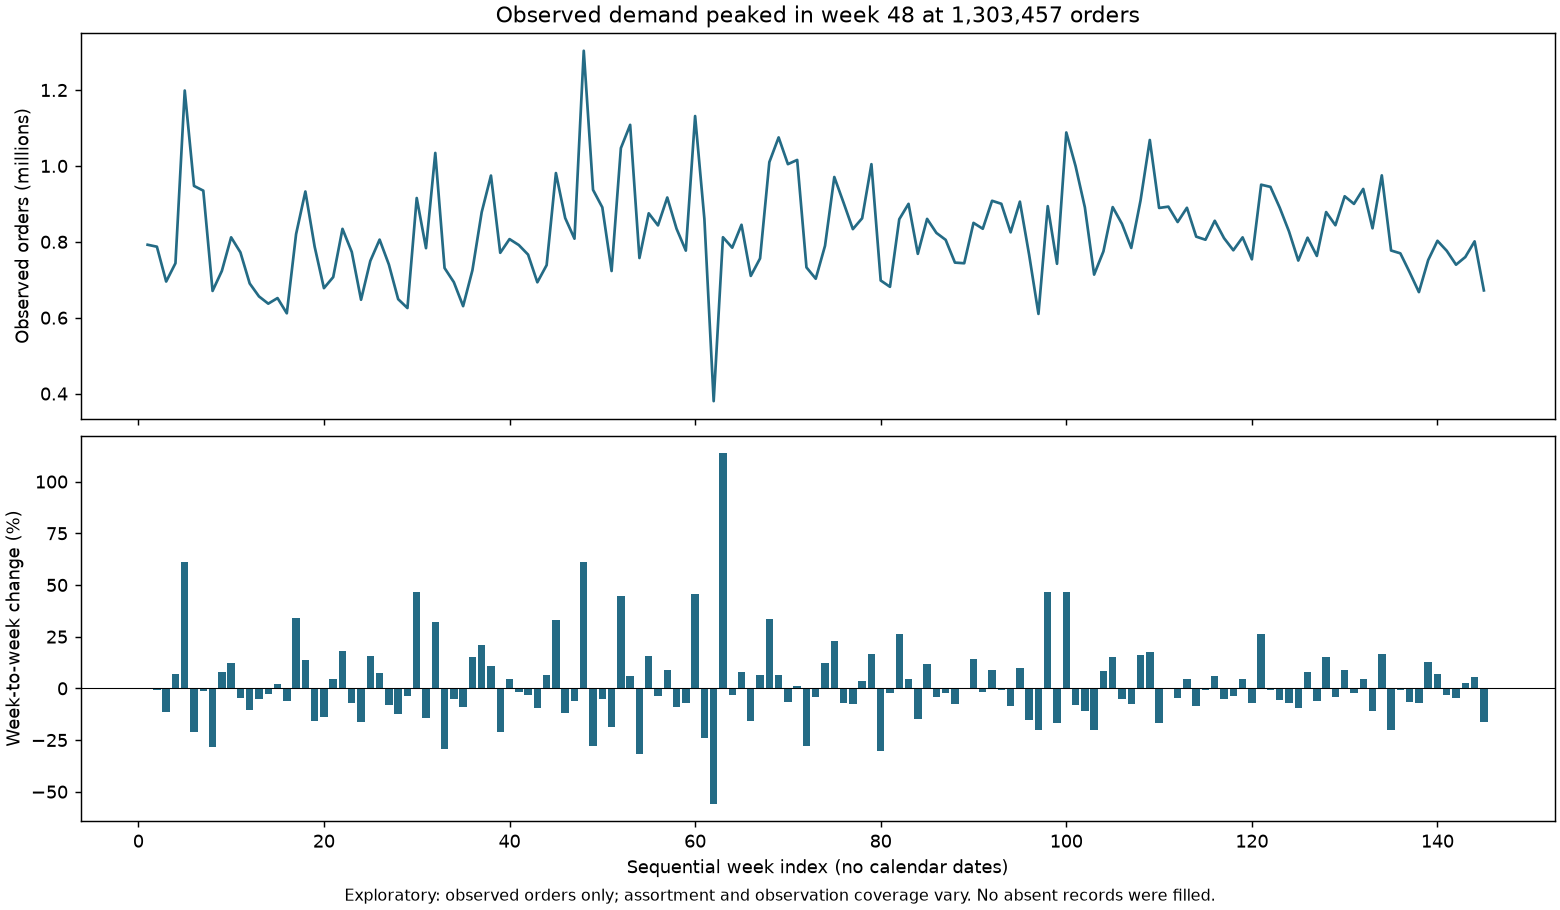

week,orders,observations,change_orders,change_pct
1,"792,261","2,922",unavailable,unavailable
2,"787,084","2,896","-5,177",-0.65
3,"695,262","2,899","-91,822",-11.67
4,"743,529","2,889","48,267",6.94
5,"1,198,675","2,859","455,146",61.21
6,"947,288","2,846","-251,387",-20.97
7,"934,803","2,795","-12,485",-1.32
8,"670,518","2,786","-264,285",-28.27
9,"723,243","2,854","52,725",7.86
10,"811,825","2,859","88,582",12.25


In [4]:
s = result['weekly_summary']
display(Markdown(f"**Observed facts:** Peak demand was {s['peak']['orders']:,} orders in week {s['peak']['week']}; the trough was {s['trough']['orders']:,} in week {s['trough']['week']}. Demand changed from {s['first']['orders']:,} in week 1 to {s['last']['orders']:,} in week 145 ({s['first_to_last_pct']:+.2f}%). The first ten observed weeks averaged {s['first_block_average']:,.0f} recorded orders; the final ten averaged {s['last_block_average']:,.0f}."))
display(Markdown(f"**Unusual observed transitions:** Largest percentage rise: week {s['largest_pct_increase']['week']} ({s['largest_pct_increase']['change_pct']:+.2f}%); largest decline: week {s['largest_pct_decrease']['week']} ({s['largest_pct_decrease']['change_pct']:+.2f}%). These are descriptive extremes, not statistically established anomalies or calendar events."))
table(s['largest_five_absolute_pct_changes'], ['week','orders','observations','change_orders','change_pct'])
show(weekly_figure(result), 'weekly_demand')
table(result['weekly'], ['week','orders','observations','change_orders','change_pct'])

## Category concentration: smallest prefix reaching 80%

Rank all categories by recorded orders, breaking ties lexically. Include the category crossing 80%; excluding it would understate the set needed to reach the target. This is a ranked aggregate selection, not a filter on the source data. The previous prefix's share makes the crossing rule auditable.

**Observed concentration:** 5 of 14 categories account for 81.40% of observed orders: Beverages, Rice Bowl, Sandwich, Salad, Pizza. The previous prefix covers 75.22%.

key,orders,share_pct,cumulative_pct
Beverages,"40,480,525",33.86,33.86
Rice Bowl,"20,874,063",17.46,51.32
Sandwich,"17,636,782",14.75,66.07
Salad,"10,944,336",9.15,75.22
Pizza,"7,383,720",6.18,81.40
Other Snacks,"4,766,293",3.99,85.39
Starters,"4,649,122",3.89,89.27
Extras,"3,984,979",3.33,92.61
Seafood,"2,715,714",2.27,94.88
Desert,"1,940,754",1.62,96.50


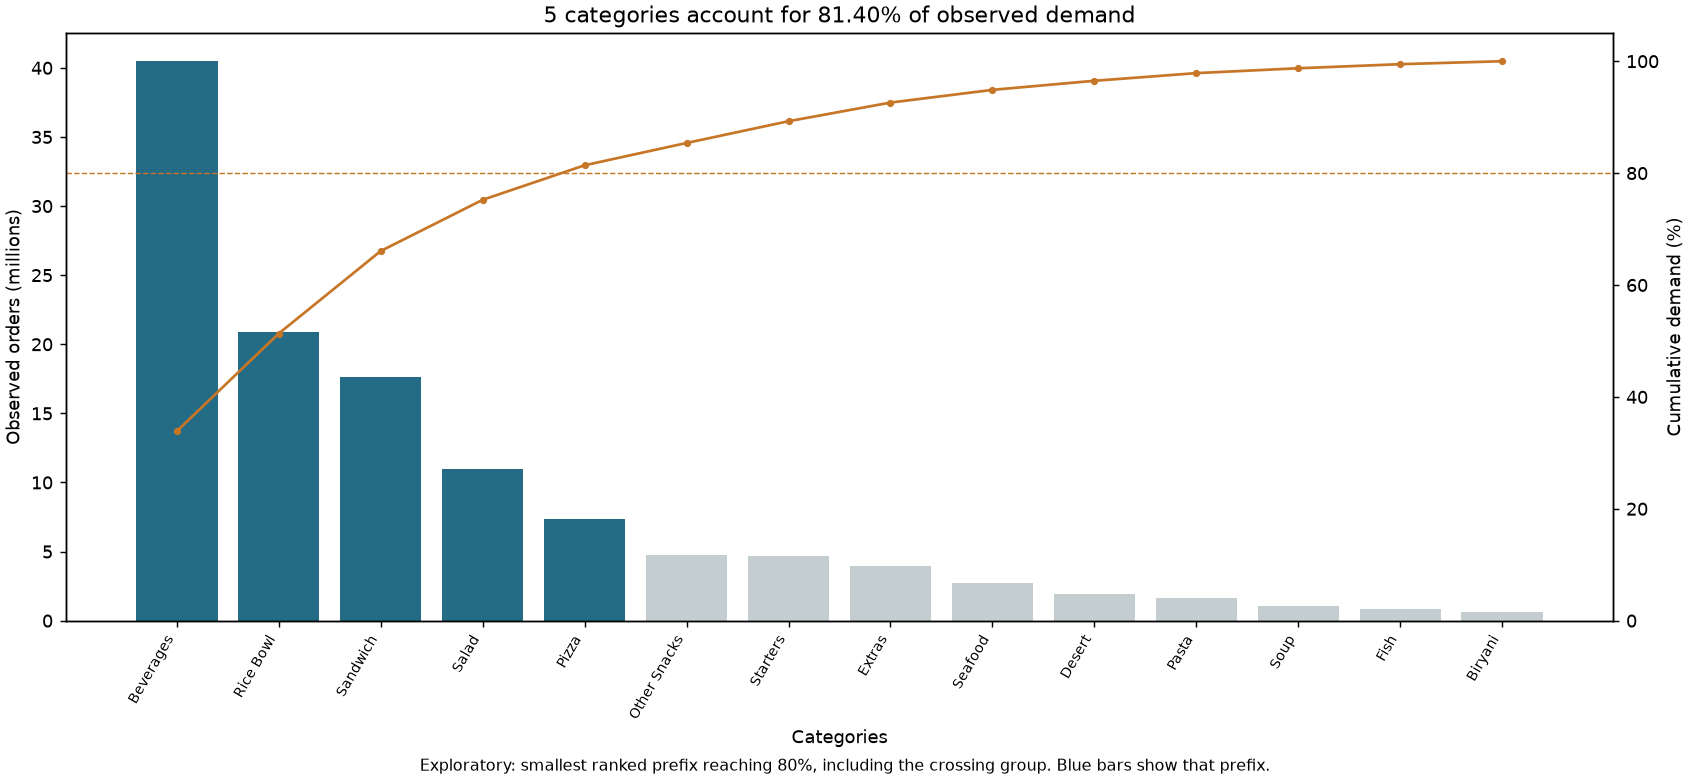

Aggregate-selection accounting: {'groups_before': 14, 'groups_selected': 5, 'groups_remaining': 9, 'orders_before': 119557485, 'orders_selected': 97319426, 'orders_remaining': 22238059}


In [5]:
c = result['categories']
display(Markdown(f"**Observed concentration:** {c['threshold_count']} of {len(c['ranking'])} categories account for {c['selected_share_pct']:.2f}% of observed orders: {', '.join(c['selected_keys'])}. The previous prefix covers {c['previous_share_pct']:.2f}%."))
table(c['ranking'], ['key','orders','share_pct','cumulative_pct'])
show(pareto_figure(result, 'categories', 'Categories'), 'category_pareto')
print('Aggregate-selection accounting:', c['selection_accounting'])

## Meal concentration

Apply the same full-demand denominator and threshold-crossing rule to meal IDs. IDs are coded meal labels, not names or continuous measurements. The complete ranking is retained; the highlighted prefix is descriptive concentration, not a recommendation to discontinue the remainder.

**Observed concentration:** 22 of 51 meals account for 81.18% of recorded demand; 21 meals account for 79.72%. Selected IDs: 2290, 1885, 1754, 1993, 1109, 2707, 1971, 2826, 1727, 1062, 2664, 2490, 2569, 1778, 1962, 2539, 2581, 2322, 2640, 1230, 1207, 1558.

key,category,orders,share_pct,cumulative_pct
2290,Rice Bowl,"9,770,303",8.17,8.17
1885,Beverages,"8,346,246",6.98,15.15
1754,Sandwich,"6,818,059",5.70,20.86
1993,Beverages,"6,656,856",5.57,26.42
1109,Rice Bowl,"6,367,773",5.33,31.75
2707,Beverages,"5,932,792",4.96,36.71
1971,Sandwich,"5,728,620",4.79,41.50
2826,Sandwich,"5,090,103",4.26,45.76
1727,Rice Bowl,"4,735,987",3.96,49.72
1062,Beverages,"4,712,795",3.94,53.66


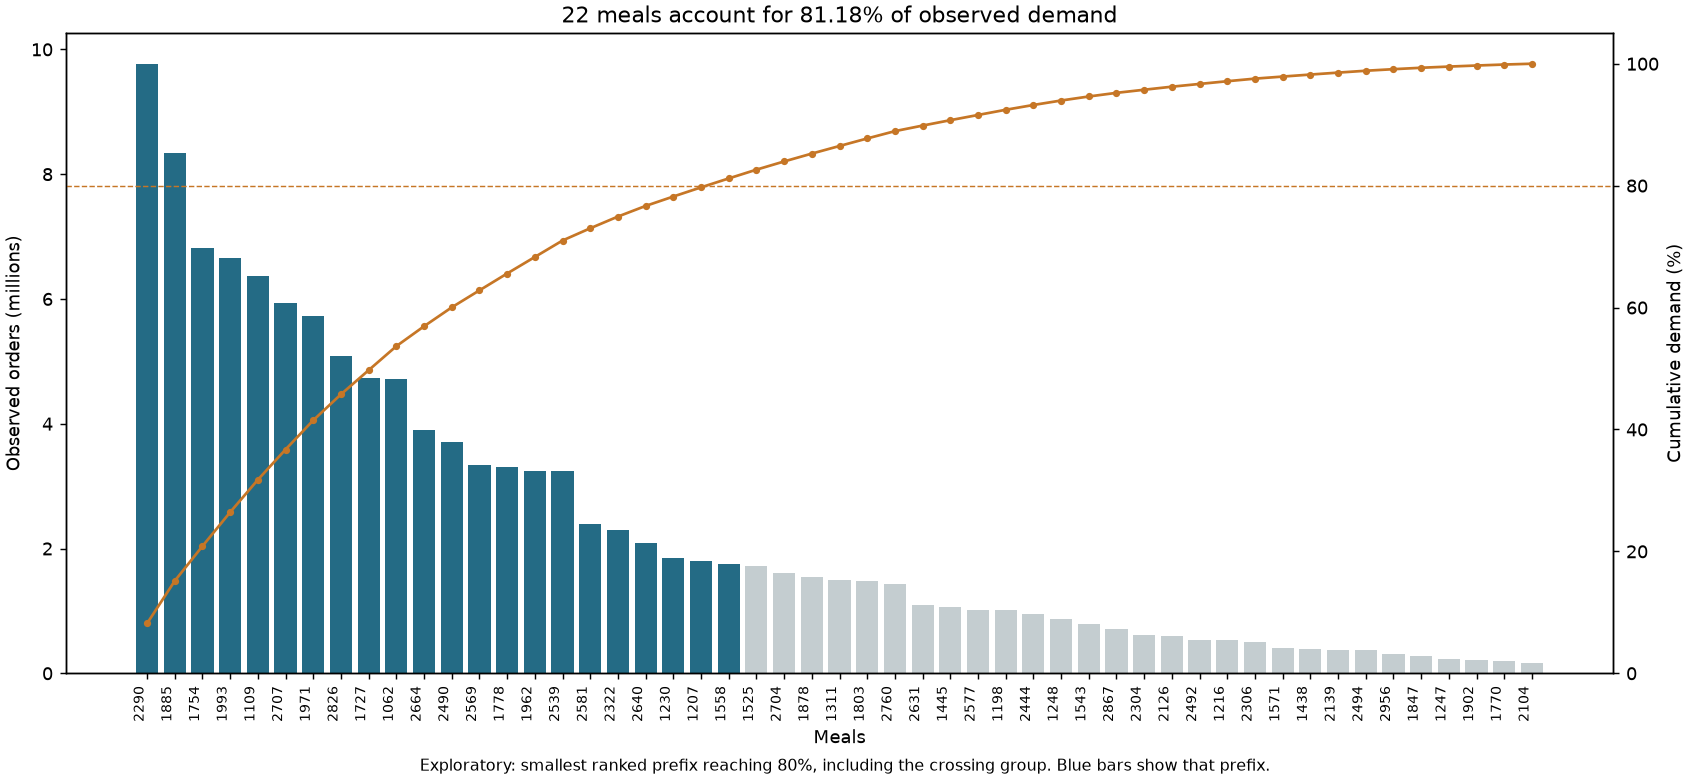

Aggregate-selection accounting: {'groups_before': 51, 'groups_selected': 22, 'groups_remaining': 29, 'orders_before': 119557485, 'orders_selected': 97058907, 'orders_remaining': 22498578}


In [6]:
m = result['meals']
display(Markdown(f"**Observed concentration:** {m['threshold_count']} of {len(m['ranking'])} meals account for {m['selected_share_pct']:.2f}% of recorded demand; {m['threshold_count']-1} meals account for {m['previous_share_pct']:.2f}%. Selected IDs: {', '.join(m['selected_keys'])}."))
table(m['ranking'], ['key','category','orders','share_pct','cumulative_pct'])
show(pareto_figure(result, 'meals', 'Meals'), 'meal_pareto')
print('Aggregate-selection accounting:', m['selection_accounting'])

## Fulfilment-center demand and observation exposure

Aggregate all observed meals within a center-week **before** averaging weeks. The denominator is the number of recorded center-weeks, not rows, and missing weeks are not filled. These center totals therefore measure recorded demand, not capacity utilization, profitability, or efficiency. Operating area is context only; its physical unit is unspecified.

**Observed facts:** Center 13 has the highest total, 4,296,545 orders over 145 observed weeks (29,631.34 per observed week). The leader by observed weekly average is center 13.

center_id,center_type,observed_weeks,missing_global_weeks,orders,average_observed_week_orders
24,TYPE_B,120,25,"1,997,535","16,646.12"


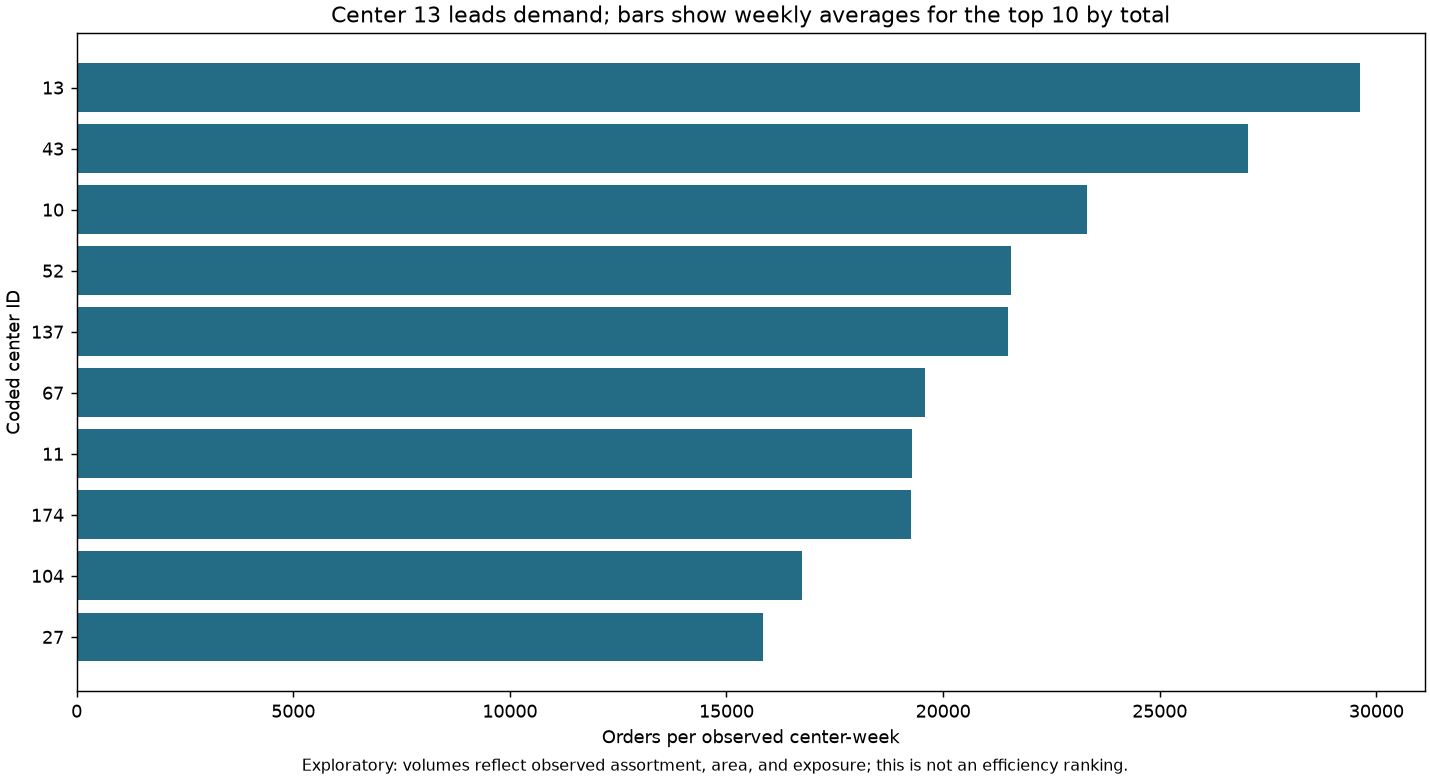

Chart display only: 10 of 77 centers; orders shown 30995790 ; remaining orders 88561695 ; no source rows removed.


center_id,center_type,orders,observed_weeks,average_observed_week_orders,op_area
13,TYPE_B,"4,296,545",145,"29,631.34",6.70
43,TYPE_A,"3,920,294",145,"27,036.51",5.10
10,TYPE_B,"3,381,018",145,"23,317.37",6.30
52,TYPE_B,"3,125,835",145,"21,557.48",5.60
137,TYPE_A,"3,117,478",145,"21,499.85",4.40
67,TYPE_B,"2,839,493",145,"19,582.71",7.00
11,TYPE_A,"2,797,300",145,"19,291.72",3.70
174,TYPE_A,"2,792,587",145,"19,259.22",7.00
104,TYPE_A,"2,427,542",145,"16,741.67",4.50
27,TYPE_A,"2,297,698",145,"15,846.19",4.50


In [7]:
centers = result['centers']; leader = centers[0]
by_weekly = sorted(centers, key=lambda r: (-r['average_observed_week_orders'], r['center_id']))
display(Markdown(f"**Observed facts:** Center {leader['center_id']} has the highest total, {leader['orders']:,} orders over {leader['observed_weeks']} observed weeks ({leader['average_observed_week_orders']:,.2f} per observed week). The leader by observed weekly average is center {by_weekly[0]['center_id']}."))
incomplete = [r for r in centers if r['missing_global_weeks']]
table(incomplete, ['center_id','center_type','observed_weeks','missing_global_weeks','orders','average_observed_week_orders'])
show(center_figure(result), 'center_demand')
print('Chart display only: 10 of', len(centers), 'centers; orders shown', sum(r['orders'] for r in centers[:10]), '; remaining orders', sum(r['orders'] for r in centers[10:]), '; no source rows removed.')
table(centers, ['center_id','center_type','orders','observed_weeks','average_observed_week_orders','op_area'])

## Center-type performance: unequal group sizes and recorded exposure

Show type totals alongside orders per **observed center-week**, and the median of individual center weekly averages. The exposure-weighted average and the median center are different summaries. Neither controls for area, meal assortment, missing observations, or other location differences; no test of a center-type effect is performed.

**Observed contrast:** TYPE_A leads total volume with 68,978,517 orders from 43 centers. TYPE_B leads orders per recorded center-week at 13,951.66, across 15 centers. This is an unadjusted descriptive comparison.

center_type,centers,orders,observed_center_weeks,orders_per_observed_center_week,median_center_weekly_average,op_area_min,op_area_median,op_area_max
TYPE_A,43,"68,978,517","6,235","11,063.11","10,007.21",2.40,4.00,7.00
TYPE_B,15,"29,996,073","2,150","13,951.66","13,148.52",3.60,4.40,7.00
TYPE_C,19,"20,582,895","2,755","7,471.11","7,006.34",0.90,3.00,5.10


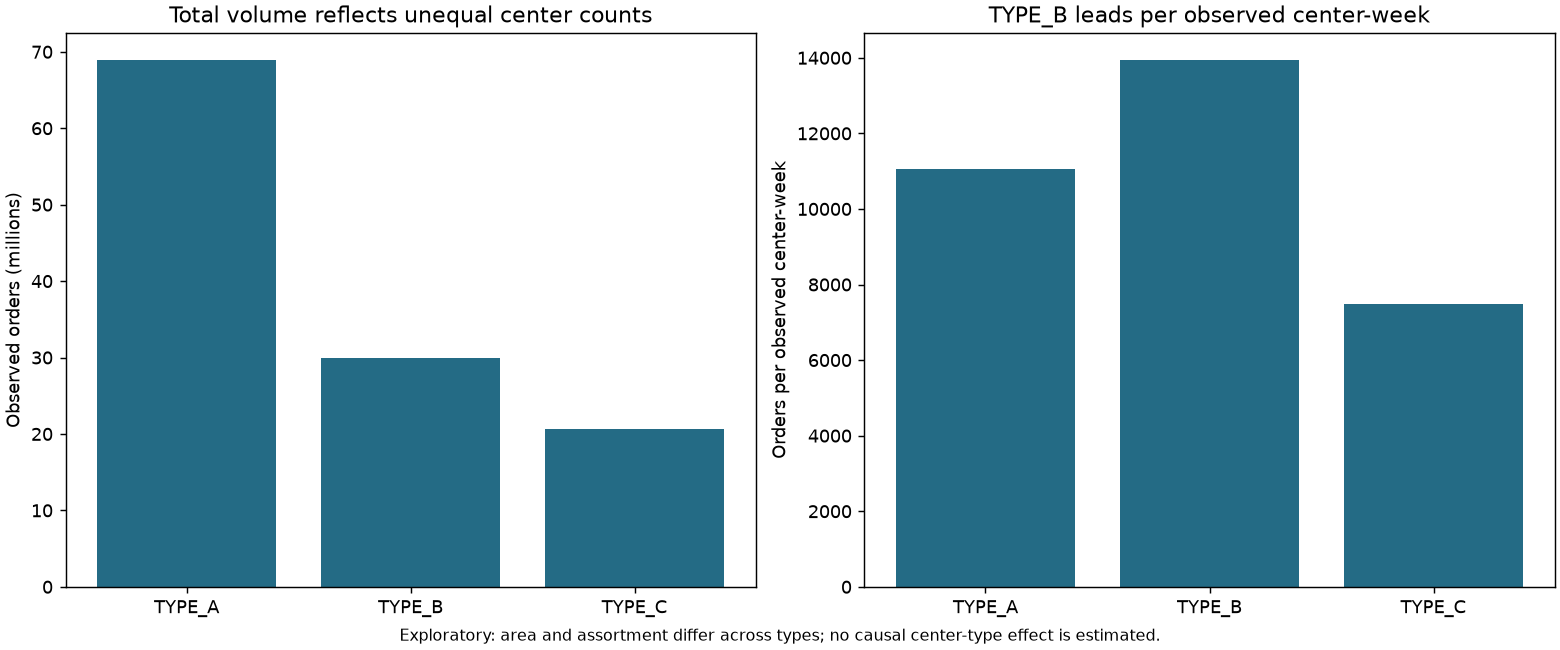

In [8]:
types = result['center_types']
total_leader = max(types, key=lambda r: r['orders'])
weekly_leader = max(types, key=lambda r: r['orders_per_observed_center_week'])
display(Markdown(f"**Observed contrast:** {total_leader['center_type']} leads total volume with {total_leader['orders']:,} orders from {total_leader['centers']} centers. {weekly_leader['center_type']} leads orders per recorded center-week at {weekly_leader['orders_per_observed_center_week']:,.2f}, across {weekly_leader['centers']} centers. This is an unadjusted descriptive comparison."))
table(types, ['center_type','centers','orders','observed_center_weeks','orders_per_observed_center_week','median_center_weekly_average','op_area_min','op_area_median','op_area_max'])
show(type_figure(result), 'center_type_demand')

## Exploratory interpretation, limitations and stopping boundary

Observed volumes fluctuate substantially, with clear concentration across categories and meals. Center totals and per-observed-week comparisons answer different exposure questions. Follow-up explanations require later authorized work: this notebook does not attribute changes to promotions, discounts, calendar seasons, or center type.

Missing series weeks remain unknown observations; category and meal portfolios can change over time. Phase 5 retained extreme demand and pricing anomalies. The period lacks calendar dates, locations are coded, and operating-area units are unspecified. The preceding Phase 6–7 sections are descriptive. Phase 8 comparisons follow with explicit inference limits. No causal inference, recommendations, final-report claims or forecasting is included.

Actual use of the installed exploratory-data-analysis skill: manifest and full enriched-file profile, plus its guidance on observation units, bounded scans, missingness and noncausal wording. Attribution retained: Kassis et al. (2026), *Scientific Agent Skills: A Library of Procedural Knowledge for Research Agents*, https://doi.org/10.48550/arXiv.2609.00065 (source verified in Phase 3).

## Phase 7: descriptive KPI definitions and coverage

Use the same hash-validated Phase 5 input. Total orders sum all recorded observations. Average weekly demand is the mean of **weekly totals**, over observed global weeks, rather than a row-level mean. No missing weeks are filled.

Revenue proxy is the sum of checkout price × order count, computed using decimal prices. It assumes the recorded price applies to every unit in its row. Currency is unknown; this is neither realized accounting revenue nor profit. Invalid-price coverage is explicit; an incomplete full proxy is unavailable rather than mislabeled as a complete total.

Discount rates retain `(base_price - checkout_price) / base_price`, including negatives when checkout exceeds base. The headline is the unweighted mean of valid **row rates**, not an order-weighted rate or ratio of summed prices. Invalid/nonpositive base prices are excluded from that denominator and counted, with their order coverage. Price anomalies are retained unchanged.

Email/homepage shares are fractions of **observations** flagged 1, not shares of orders or individual weeks. No comparison of demand across promotion groups is performed.

In [9]:
from src.analysis.kpis import calculate_prepared_kpis, kpi_table, write_kpi_outputs
kpis = calculate_prepared_kpis(ROOT)
KPI_OUT = ROOT / 'data/processed/phase7'
write_kpi_outputs(kpis, KPI_OUT)
assert kpis['observation_count'] == result['input_rows']
assert kpis['total_orders'] == result['input_orders']
table(kpi_table(kpis), ['metric','value','unit','denominator'])
display(Markdown(f"**Observed KPI values:** {kpis['total_orders']:,} orders; {kpis['average_weekly_demand']:,.2f} orders per observed week; revenue proxy {kpis['revenue_proxy']} price units (currency unspecified). Mean signed discount: {100*kpis['discount_mean_rate']:.4f}%; email-promotion share: {100*kpis['email_promotion_share']:.4f}%; homepage-feature share: {100*kpis['homepage_feature_share']:.4f}%."))
table([{'metric':'Revenue','valid_rows':kpis['revenue_valid_rows'],'invalid_rows':kpis['revenue_invalid_rows'],'excluded_orders':kpis['revenue_excluded_orders']},
       {'metric':'Discount','valid_rows':kpis['discount_valid_rows'],'invalid_rows':kpis['discount_invalid_rows'],'excluded_orders':kpis['discount_excluded_orders']}],
      ['metric','valid_rows','invalid_rows','excluded_orders'])
display(Markdown(f"**Signed discounts:** {kpis['negative_discount_rows']:,} negative-rate rows retained; minimum {100*kpis['discount_min_rate']:.4f}%, median {100*kpis['discount_median_rate']:.4f}%, maximum {100*kpis['discount_max_rate']:.4f}%. No prices or rates were clamped. These are descriptive rates, not evidence of promotion effects."))

metric,value,unit,denominator
Total orders,"119,557,485",orders,all recorded observations
Average weekly demand,"824,534.38",orders per observed global week,145
Revenue proxy (not profit),31922771040.11,unspecified price units,456548 valid rows; 0 invalid
Mean signed discount rate,0.06,fraction,"456,548"
Email-promotion share,0.08,fraction of observations,"456,548"
Homepage-feature share,0.11,fraction of observations,"456,548"


**Observed KPI values:** 119,557,485 orders; 824,534.38 orders per observed week; revenue proxy 31922771040.11 price units (currency unspecified). Mean signed discount: 5.7195%; email-promotion share: 8.1152%; homepage-feature share: 10.9200%.

metric,valid_rows,invalid_rows,excluded_orders
Revenue,"456,548",0,0
Discount,"456,548",0,0


**Signed discounts:** 116,101 negative-rate rows retained; minimum -72.7898%, median 0.1412%, maximum 99.0609%. No prices or rates were clamped. These are descriptive rates, not evidence of promotion effects.

## Meal demand volatility: full per-meal CV table

For each meal, pool its **observed center-meal-week order counts** and compute sample standard deviation (`ddof=1`) / arithmetic mean. Rows receive equal weight. This combines cross-center differences with week-to-week variation and is not a pure temporal volatility measure. Changing center coverage, missing observations and retained demand extremes affect it.

CV is unavailable for fewer than two observations, or a mean ≤ 1e-12 orders; negative/non-finite demand is rejected. Constant positive demand yields CV=0. No zero filling, weighting, clipping, transformation, volatility segmentation, or safety-stock recommendations are made. The complete table is sorted by meal ID, not used as a Phase 9 risk ranking. These target-derived descriptive statistics are not forecasting features.

In [10]:
table(kpis['volatility'], ['meal_id','observations','observed_centers','observed_weeks','mean_orders','sample_std_orders','cv','unavailable_reason'])
valid_cv = [r for r in kpis['volatility'] if r['cv'] is not None]
assert sum(r['observations'] for r in kpis['volatility']) == kpis['observation_count']
display(Markdown(f"**Coverage:** {len(valid_cv)} of {len(kpis['volatility'])} meals have defined CV. Values range from {min(r['cv'] for r in valid_cv):.4f} to {max(r['cv'] for r in valid_cv):.4f}. See every meal's mean, sample standard deviation and sample size above. CVs are unitless and are descriptive only."))
assert kpis['rows_removed'] == kpis['values_clamped'] == kpis['weeks_imputed'] == 0
print('Phase 7 descriptive tables saved; Phase 8 comparisons appear in the following section.')

meal_id,observations,observed_centers,observed_weeks,mean_orders,sample_std_orders,cv,unavailable_reason
1062,"11,137",77,145,423.17,245.96,0.58,unavailable
1109,"11,134",77,145,571.92,526.85,0.92,unavailable
1198,"4,206",36,145,242.10,191.29,0.79,unavailable
1207,"10,806",77,145,166.65,144.61,0.87,unavailable
1216,"9,695",77,145,55.03,43.94,0.80,unavailable
1230,"10,746",77,145,171.60,148.64,0.87,unavailable
1247,"7,184",76,145,32.28,22.60,0.70,unavailable
1248,"9,939",77,145,88.01,98.92,1.12,unavailable
1311,"4,682",36,145,318.17,256.90,0.81,unavailable
1438,"4,385",35,145,90.10,74.39,0.83,unavailable


**Coverage:** 51 of 51 meals have defined CV. Values range from 0.5812 to 1.4453. See every meal's mean, sample standard deviation and sample size above. CVs are unitless and are descriptive only.

Phase 7 descriptive tables saved; Phase 8 comparisons appear in the following section.


## Phase 8: observed promotion comparisons within meal-center context

Use the custom `promotion-impact-analysis` skill at `.github/skills/promotion-impact-analysis/SKILL.md`. Population: historical weeks 1–145; unit: an observed center-meal-week. Preserve all signed discounts and original orders.

**Design fixed before calculation:** a binary comparison includes contexts with ≥5 observations in each state. Give every eligible meal-center equal weight; average its demand separately in each state before averaging across contexts. Percentage difference uses the equal-context unpromoted mean as denominator. Pooled row means/medians/IQR and counts are shown separately. No promotion or discount coefficient is interpreted as causal, and this comparison does not adjust for discount, time, or the other promotion.

**Mann–Whitney:** two-sided, asymptotic, tie-corrected, continuity correction enabled. The reported U compares promoted rows with unpromoted rows pooled within eligible contexts. Its p-value is an **IID reference only**, since repeated weeks, shared week shocks and context mixing violate independent-row calibration. Do not read this as a test of matched pairs or automatically as a test of medians. Numerical p=0 means floating underflow, not an exact zero.

**Dependence-aware uncertainty:** linearize the equal-context mean difference into weekly residual-contrast scores using fixed original state counts. Resample joint week blocks for all contexts, retaining shared shocks and local serial dependence; missing records add no observed residual, not zero orders. Use 2,000 seeded circular block draws, primary length 8 weeks, sensitivity lengths 4 and 12. Pointwise intervals are 95%; 99% intervals apply the Bonferroni threshold for five predeclared contrasts (two binary, three combined versus neither). Percent intervals scale the difference bounds by the original baseline and are not a full ratio-estimator interval. These are approximate, conditional on weak stationarity/dependence assumptions; they do not remove confounding or represent a random sample of centers. Circular wrapping is computational, not evidence of seasonality.

Minimum counts improve descriptive coverage, not independence. All exclusions below are comparison-specific scope accounting, with no source deletion. The Spearman p-value is likewise an IID reference, not confirmatory significance. See SciPy documentation: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html and https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html.

In [11]:
from src.statistics.promotions import analyze as analyze_promotions
promotion = analyze_promotions(ROOT)
assert promotion['rows'] == 456548 and promotion['total_orders'] == 119557485
assert promotion['negative_discounts'] == 116101
for flag in ['email','homepage']:
    comparison = promotion[flag]
    display(Markdown('### ' + flag.capitalize() + ' promotion'))
    table([comparison['coverage']], list(comparison['coverage']))
    table([{'state':'flagged','mean_orders':comparison['promoted_context_mean']}, {'state':'not flagged','mean_orders':comparison['reference_context_mean']}], ['state','mean_orders'])
    display(Markdown(f"**Equal-context association:** {comparison['difference_orders']:+.2f} orders ({comparison['percentage_difference']:+.2f}%). Median of context-specific differences: {comparison['median_context_difference']:.2f}; mean within-context probability of superiority: {comparison['mean_within_context_probability_superiority']:.4f}. These are different estimands from pooled row means below."))
    table([{'state':'flagged',**comparison['pooled_promoted']}, {'state':'not flagged',**comparison['pooled_reference']}], ['state','n','mean','median','q25','q75'])
    table([comparison['mann_whitney_pooled_reference']], ['u','iid_reference_p','p_underflow','calibration'])
    table(comparison['uncertainty']['sensitivity'], ['block_weeks','repetitions','difference_ci95','difference_ci99_family5','percentage_ci95','family99_excludes_zero'])
    display(Markdown(f"**Uncertainty:** weekly-score lag-1 correlation is {comparison['uncertainty']['weekly_score_lag1_correlation']:.3f}. Check block-length sensitivity rather than relying on the pooled IID p-value. The approximate family intervals concern the observed contrast under the resampling assumptions; magnitude and operational relevance remain separate from significance."))

### Email promotion

input_series,eligible_series,excluded_series,input_rows,comparison_rows,rows_outside_comparison,input_orders,comparison_orders,orders_outside_comparison,min_observations_per_state_per_context,contexts_lacking_a_state,contexts_with_both_but_below_minimum,no_rows_deleted_from_source
"3,597","2,482","1,115","456,548","335,870","120,678","119,557,485","90,033,133","29,524,352",5,767,348,1


state,mean_orders
flagged,621.77
not flagged,214.25


**Equal-context association:** +407.52 orders (+190.21%). Median of context-specific differences: 195.65; mean within-context probability of superiority: 0.8691. These are different estimands from pooled row means below.

state,n,mean,median,q25,q75
flagged,"36,089",630.81,337.00,161.00,730.00
not flagged,"299,781",224.39,135.00,55.00,296.00


...

**Equal-context association:** +388.97 orders (+158.87%). Median of context-specific differences: 189.08; mean within-context probability of superiority: 0.8324. These are different estimands from pooled row means below.

state,n,mean,median,q25,q75
flagged,"48,451",597.85,350.00,136.00,742.00
not flagged,"282,271",250.21,149.00,67.00,324.00


u,iid_reference_p,p_underflow,calibration
"9,401,139,402.50",0.00,1,"IID reference only: serial dependence, shared weeks, and context mixture invalidate a confirmatory interpretation"


block_weeks,repetitions,difference_ci95,difference_ci99_family5,percentage_ci95,family99_excludes_zero
4,"2,000","[357.4469038378662, 423.242479163961]","[351.6846303552667, 440.41295555575226]","[145.99030276785373, 172.86287002052367]",1
8,"2,000","[357.16071365483134, 424.9140216517397]","[346.3987800454172, 435.2608680241451]","[145.8734155014602, 173.54556999990533]",1
12,"2,000","[358.92758016295824, 421.02918891467925]","[351.47714899685224, 432.07121024717884]","[146.59504820747134, 171.95890663425152]",1


**Uncertainty:** weekly-score lag-1 correlation is 0.199. Check block-length sensitivity rather than relying on the pooled IID p-value. The approximate family intervals concern the observed contrast under the resampling assumptions; magnitude and operational relevance remain separate from significance.

## Combined conditions on common support

First show global condition counts and summaries as descriptive context only. Then use the same contexts for every condition: ≥5 observations in each of neither/email only/homepage only/both, and at least 30 common contexts. This prevents comparing different meal-center mixtures across the four states. The three comparisons share the same neither baseline. This is a restricted observed population; it does not isolate interaction or the contribution of either channel.

In [12]:
combined = promotion['combined']
state_rows = [{'condition':state, 'contexts':value['contexts'], **value['demand'], 'mean_discount':value['discount']['mean']} for state,value in combined['global_states'].items()]
table(state_rows, ['condition','contexts','n','mean','median','q25','q75','mean_discount'])
display(Markdown(f"**Common-support coverage:** {combined['common_four_state_contexts']} center-meal contexts satisfy the four-state minimum; sufficient under the prespecified descriptive rule: {combined['sufficient_for_comparison']}."))
for state,comparison in combined['contrasts'].items():
    display(Markdown('#### ' + state.replace('_',' ') + ' versus neither'))
    table([{'promoted_context_mean':comparison['promoted_context_mean'],'neither_context_mean':comparison['reference_context_mean'], 'difference_orders':comparison['difference_orders'],'percentage_difference':comparison['percentage_difference'], 'promoted_n':comparison['pooled_promoted']['n'],'neither_n':comparison['pooled_reference']['n']}], ['promoted_context_mean','neither_context_mean','difference_orders','percentage_difference','promoted_n','neither_n'])
    table([comparison['coverage']],list(comparison['coverage']))
    table([{'state':state,**comparison['pooled_promoted']},{'state':'neither',**comparison['pooled_reference']}],['state','n','mean','median','q25','q75'])
    table([comparison['mann_whitney_pooled_reference']],['u','iid_reference_p','p_underflow','calibration'])
    table(comparison['uncertainty']['sensitivity'],['block_weeks','difference_ci95','difference_ci99_family5','family99_excludes_zero'])

condition,contexts,n,mean,median,q25,q75,mean_discount
neither,"3,597","388,874",211.42,122.00,53.00,283.00,0.04
email_only,"2,696","17,819",431.28,229.00,107.00,473.00,0.23
homepage_only,"2,776","30,624",455.88,258.00,95.00,594.00,0.11
both,"2,489","19,231",816.25,474.00,243.00,"1,012.00",0.25


**Common-support coverage:** 490 center-meal contexts satisfy the four-state minimum; sufficient under the prespecified descriptive rule: True.

#### email only versus neither

promoted_context_mean,neither_context_mean,difference_orders,percentage_difference,promoted_n,neither_n
494.83,151.39,343.44,226.86,"4,868","50,156"


input_series,eligible_series,excluded_series,input_rows,comparison_rows,rows_outside_comparison,input_orders,comparison_orders,orders_outside_comparison,min_observations_per_state_per_context,contexts_lacking_a_state,contexts_with_both_but_below_minimum,no_rows_deleted_from_source
"3,597",490,"3,107","456,548","55,024","401,524","119,557,485","10,173,528","109,383,957",5,901,"1,051",1


...

promoted_context_mean,neither_context_mean,difference_orders,percentage_difference,promoted_n,neither_n
643.85,151.39,492.46,325.29,"7,332","50,156"


input_series,eligible_series,excluded_series,input_rows,comparison_rows,rows_outside_comparison,input_orders,comparison_orders,orders_outside_comparison,min_observations_per_state_per_context,contexts_lacking_a_state,contexts_with_both_but_below_minimum,no_rows_deleted_from_source
"3,597",490,"3,107","456,548","57,488","399,060","119,557,485","12,713,654","106,843,831",5,"1,108","1,122",1


state,n,mean,median,q25,q75
both,"7,332",636.31,393.00,229.00,715.00
neither,"50,156",160.46,107.00,53.00,203.00


u,iid_reference_p,p_underflow,calibration
"310,911,613.00",0.00,1,"IID reference only: serial dependence, shared weeks, and context mixture invalidate a confirmatory interpretation"


block_weeks,difference_ci95,difference_ci99_family5,family99_excludes_zero
4,"[441.9073784092601, 540.769883391115]","[429.0355464635557, 558.2540356855699]",1
8,"[442.7707955053765, 539.6628502880852]","[427.302197710234, 553.0158537566697]",1
12,"[445.7066904585129, 538.2981036983023]","[431.8464066397026, 552.7600552360071]",1


## Discount-demand association and promotion overlap

Spearman uses all valid signed discounts, including all 116,101 negative rates. Compare the global rank association with the descriptive distribution of within-context correlations (at least ten observations, both variables nonconstant). Do not combine their p-values or describe the mean correlation as a single adjusted correlation.

Promotion and discount overlap is investigated with mean, median and IQR of signed rates, plus the other marketing flag's prevalence. Larger discounts alongside promotion provide evidence of confounding potential; this analysis cannot assign a portion of the demand difference to any channel or price change.

In [13]:
sp = promotion['spearman']
table([sp], ['n','rho','iid_reference_p','p_underflow','calibration'])
table([sp['within_context']], list(sp['within_context']))
display(Markdown(f"**Observed global association:** Spearman rho={sp['rho']:.4f}, a weak positive monotonic relationship. The nominal p-value underflows numerically; dependence and large sample size prevent reading it as practical importance or calibrated confirmatory evidence. Within-context correlations describe a different association: mean rho={sp['within_context']['mean_rho_equal_context']:.4f}, median={sp['within_context']['median_rho']:.4f}. Correlation does not establish a causal relationship."))
for flag in ['email','homepage']:
    rows = [{'state':value, **data['discount'], 'other_flag_share':data['other_flag_share']} for value,data in promotion[flag]['overlap'].items()]
    display(Markdown('**Global overlap: ' + flag + '**'))
    table(rows,['state','n','mean','median','q25','q75','other_flag_share'])
    comparison=promotion[flag]
    table([{'state':'flagged',**comparison['discount_promoted']},{'state':'not flagged',**comparison['discount_reference']}],['state','n','mean','median','q25','q75'])
display(Markdown("**Limitations and business meaning:** The observed differences are large enough to matter for planning review, but they are not isolated marketing contributions or forecasts. Discount overlap, joint channels, time changes, selection into promotions, uneven observation coverage, retained extremes, serial dependence, shared shocks, and unknown calendar dates remain. Bootstrap intervals are approximate and do not adjust systematic confounding; extending block length does not prove all dependence is captured. No sales margin, campaign cost, or realized stockout/waste outcome is available, so no ROI, inventory quantity or safety-stock recommendation follows. This Phase 8 section does not set inventory quantities; Phase 9 follows."))
assert promotion['negative_discounts'] == 116101
print('Phase 8 results saved in ignored data/processed/phase8; no raw values altered.')

n,rho,iid_reference_p,p_underflow,calibration
"456,548",0.12,0.00,1,IID reference only; repeated observations mean confirmatory significance is not established


eligible_contexts,excluded_contexts,eligible_rows,excluded_rows,eligible_orders,excluded_orders,mean_rho_equal_context,median_rho,positive_contexts,interpretation
"3,571",26,"456,415",133,"119,550,125","7,360",0.26,0.26,"3,177","Descriptive distribution of within-context monotonic associations, not a pooled adjusted correlation or combined significance test"


**Observed global association:** Spearman rho=0.1218, a weak positive monotonic relationship. The nominal p-value underflows numerically; dependence and large sample size prevent reading it as practical importance or calibrated confirmatory evidence. Within-context correlations describe a different association: mean rho=0.2629, median=0.2601. Correlation does not establish a causal relationship.

**Global overlap: email**

state,n,mean,median,q25,q75,other_flag_share
0,"419,498",0.04,0.00,-0.00,0.01,0.07
1,"37,050",0.24,0.24,0.16,0.33,0.52


...

**Global overlap: homepage**

state,n,mean,median,q25,q75,other_flag_share
0,"406,693",0.04,0.00,-0.00,0.01,0.04
1,"49,855",0.17,0.17,0.01,0.28,0.39


state,n,mean,median,q25,q75
flagged,"48,451",0.17,0.17,0.01,0.28
not flagged,"282,271",0.04,0.00,-0.00,0.01


**Limitations and business meaning:** The observed differences are large enough to matter for planning review, but they are not isolated marketing contributions or forecasts. Discount overlap, joint channels, time changes, selection into promotions, uneven observation coverage, retained extremes, serial dependence, shared shocks, and unknown calendar dates remain. Bootstrap intervals are approximate and do not adjust systematic confounding; extending block length does not prove all dependence is captured. No sales margin, campaign cost, or realized stockout/waste outcome is available, so no ROI, inventory quantity or safety-stock recommendation follows. This Phase 8 section does not set inventory quantities; Phase 9 follows.

Phase 8 results saved in ignored data/processed/phase8; no raw values altered.


## Phase 9: inventory-planning attention from volume AND volatility

Reuse the **exact per-meal CVs from Phase 7**, without redefining the sample or filling missing weeks. CV is sample std/mean over recorded center-meal-week orders, mixing center differences and time variation. Volume is total recorded orders across weeks 1–145. It is not an estimate of demand in unrecorded availability periods.

**Threshold rule specified before segmentation:** the unweighted median across all 51 meals for each dimension; high includes equality (`>=`), low is strictly below. These relative screening cutoffs are transparent portfolio conventions, not validated inventory-risk or service-level limits. Reject undefined/nonfinite CVs rather than assigning them to a low quadrant. All actual meal CVs are defined.

The primary review group must satisfy **both high volume and high CV**. Within it, sort by volume descending, then CV descending and numeric ID for ties. This prioritizes inventory exposure rather than ranking by CV alone. High-volume/low-CV meals still require reliable replenishment; low-volume/high-CV meals are not automatic candidates for large buffers. The source has coded IDs plus category/cuisine, but no meal names; none are invented.

In [14]:
from src.analysis.inventory import analyze_inventory, inventory_figure
inventory = analyze_inventory(ROOT)
assert inventory['total_meals'] == 51
assert inventory['total_orders'] == result['input_orders']
assert sum(r['observations'] for r in inventory['meals']) == result['input_rows']
assert inventory['missing_weeks_filled'] == 0
display(Markdown(f"**Thresholds:** high volume ≥ {inventory['thresholds']['volume_orders']:,} recorded orders; high CV ≥ {inventory['thresholds']['cv']:.8f}. Equality is high. These are relative meal medians, not safety-stock thresholds."))
table(inventory['segment_summary'], ['segment','meals','orders','observations','demand_share_pct'])
print('Meal volume/CV metadata combination:', inventory['metadata_combination'])
table(inventory['meals'], ['meal_id','meal_name','category','cuisine','orders','cv','observations','observed_centers','observed_weeks','segment','interpretation'])

**Thresholds:** high volume ≥ 1,489,681 recorded orders; high CV ≥ 0.87774049. Equality is high. These are relative meal medians, not safety-stock thresholds.

segment,meals,orders,observations,demand_share_pct
high volume / high volatility,14,"54,918,637","149,177",45.93
high volume / low volatility,12,"48,502,252","122,939",40.57
low volume / high volatility,12,"8,644,891","95,061",7.23
low volume / low volatility,13,"7,491,705","89,371",6.27


Meal volume/CV metadata combination: {'meals_before': 51, 'cv_rows_before': 51, 'meals_after': 51, 'unmatched_volume_keys': 0, 'unmatched_cv_keys': 0, 'duplicate_expansion': 0, 'orders_before': 119557485, 'orders_after': 119557485}


meal_id,meal_name,category,cuisine,orders,cv,observations,observed_centers,observed_weeks,segment,interpretation
1062,Not supplied,Beverages,Italian,"4,712,795",0.58,"11,137",77,145,high volume / low volatility,Material observed volume with lower relative variation; preserve reliable replenishment and monitor changes rather than infer low operational importance.
1109,Not supplied,Rice Bowl,Indian,"6,367,773",0.92,"11,134",77,145,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
1198,Not supplied,Extras,Thai,"1,018,280",0.79,"4,206",36,145,low volume / low volatility,"Lower observed volume and relative variation; use proportionate routine review, subject to local service and shelf-life constraints."
1207,Not supplied,Beverages,Continental,"1,800,856",0.87,"10,806",77,145,high volume / low volatility,Material observed volume with lower relative variation; preserve reliable replenishment and monitor changes rather than infer low operational importance.
1216,Not supplied,Pasta,Italian,"533,564",0.80,"9,695",77,145,low volume / low volatility,"Lower observed volume and relative variation; use proportionate routine review, subject to local service and shelf-life constraints."
1230,Not supplied,Beverages,Continental,"1,843,969",0.87,"10,746",77,145,high volume / low volatility,Material observed volume with lower relative variation; preserve reliable replenishment and monitor changes rather than infer low operational importance.
1247,Not supplied,Biryani,Indian,"231,897",0.70,"7,184",76,145,low volume / low volatility,"Lower observed volume and relative variation; use proportionate routine review, subject to local service and shelf-life constraints."
1248,Not supplied,Beverages,Indian,"874,750",1.12,"9,939",77,145,low volume / high volatility,Higher relative variation but lower observed volume; investigate selectively and avoid blanket buffer increases based on CV.
1311,Not supplied,Extras,Thai,"1,489,681",0.81,"4,682",36,145,high volume / low volatility,Material observed volume with lower relative variation; preserve reliable replenishment and monitor changes rather than infer low operational importance.
1438,Not supplied,Soup,Thai,"395,084",0.83,"4,385",35,145,low volume / low volatility,"Lower observed volume and relative variation; use proportionate routine review, subject to local service and shelf-life constraints."


## Priority meals, visual screening and operational limits

The full high-volume/high-CV list below defines the primary review group, with the first five highlighted on the chart by largest volume. This is a **screen for review**, not measured stockout/waste risk, a calibrated risk score, or an exact stock policy. A meal near either median can change segment under another reasonable cutoff.

**Supported next action:** review these meals' center-specific demand and availability each purchasing cycle before changing buffers; use the joint volume/CV evidence below. Monitor stockout and waste rates once inventory outcomes are available, and per-meal out-of-time forecast error when the forecasting phase is authorized. These are proposed monitoring KPIs, not current measured outcomes or future work performed now.

Do not treat the pooled CV as demand variability during supplier lead time. Lead-time distributions, on-hand stock, service-level targets, shelf life and inventory outcomes are unavailable. No exact safety-stock quantity is defensible from this analysis. Missing weeks remain unknown observations, and retained extreme demand can affect CV.

meal_id,category,cuisine,orders,cv,segment,interpretation
2290,Rice Bowl,Indian,"9,770,303",1.15,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
1754,Sandwich,Italian,"6,818,059",1.17,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
1109,Rice Bowl,Indian,"6,367,773",0.92,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
1971,Sandwich,Italian,"5,728,620",1.45,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
1727,Rice Bowl,Indian,"4,735,987",1.19,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
2490,Salad,Italian,"3,709,125",1.27,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
1962,Pizza,Continental,"3,235,780",0.96,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
2539,Beverages,Thai,"3,234,528",0.88,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
2581,Pizza,Continental,"2,399,000",0.96,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.
2322,Beverages,Continental,"2,298,221",0.89,high volume / high volatility,Priority review: material observed volume plus above-portfolio-median relative variation. Validate local demand and availability before inventory changes.


**Main joint-screen finding:** 14 meals account for 54,918,637 recorded orders (45.93%) while exceeding both median thresholds. The highest-volume five in that group are 2290, 1754, 1109, 1971, 1727. This combines relative variation with material volume; it does not equate high CV with measured loss.

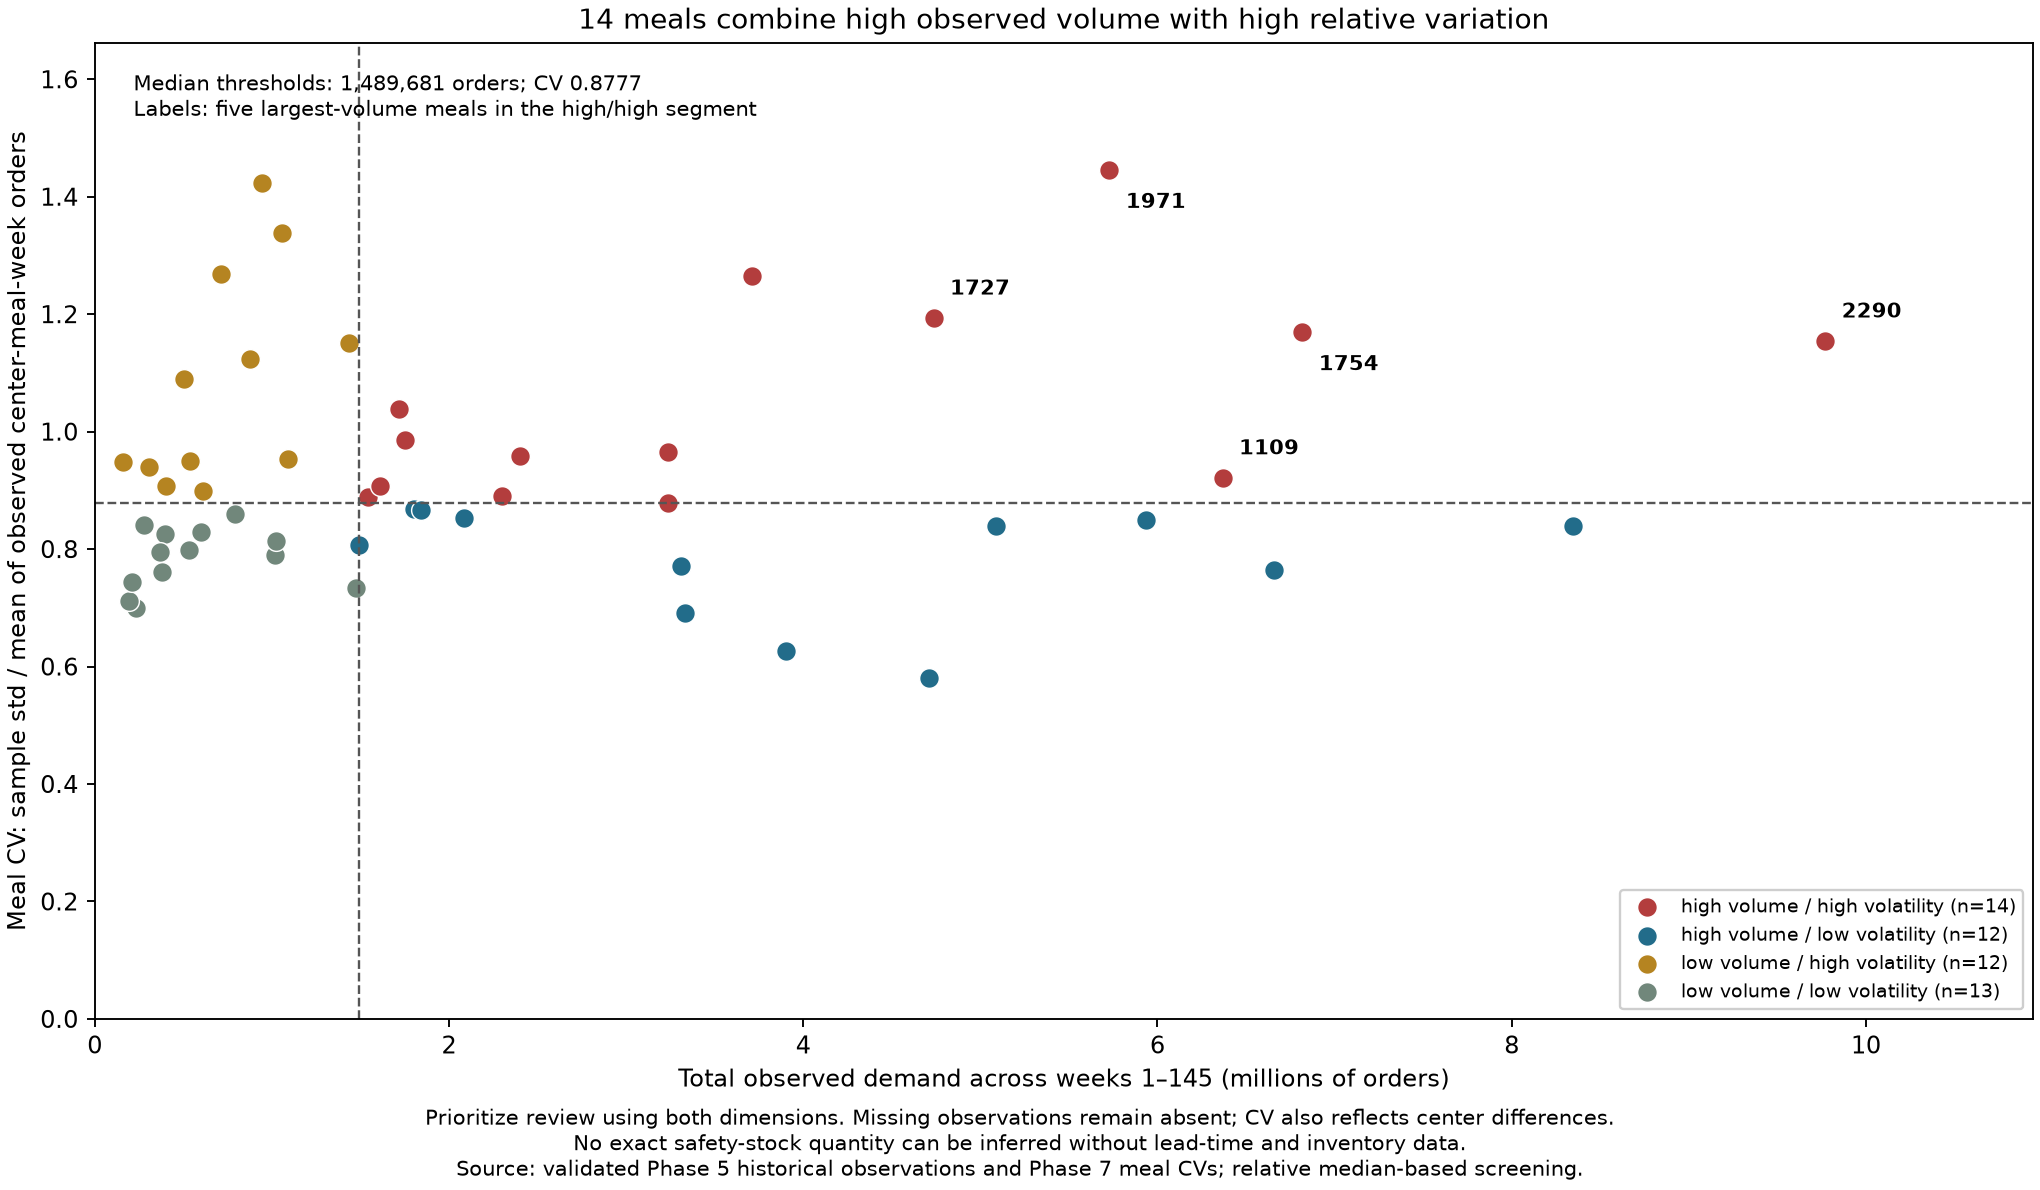

Phase 9 volume-versus-volatility figure saved. No Phase 10 model or exact safety-stock calculation performed.


In [15]:
indexed = {r['meal_id']: r for r in inventory['meals']}
priority = [indexed[meal] for meal in inventory['priority_meal_ids']]
table(priority, ['meal_id','category','cuisine','orders','cv','segment','interpretation'])
high = inventory['segment_summary'][0]
display(Markdown(f"**Main joint-screen finding:** {high['meals']} meals account for {high['orders']:,} recorded orders ({high['demand_share_pct']:.2f}%) while exceeding both median thresholds. The highest-volume five in that group are {', '.join(inventory['priority_meal_ids'][:5])}. This combines relative variation with material volume; it does not equate high CV with measured loss."))
fig = inventory_figure(inventory)
FIGURE = ROOT / 'reports/figures/demand_volume_volatility.png'
FIGURE.parent.mkdir(exist_ok=True)
fig.savefig(FIGURE, dpi=170)
display(Image(filename=str(FIGURE)))
plt.close(fig)
print('Phase 9 volume-versus-volatility figure saved. No Phase 10 model or exact safety-stock calculation performed.')

In [16]:
assert prepared_before == file_hash(ROOT / 'data/processed/train_prepared.csv')
raw_after = {name: file_hash(ROOT / 'data/raw' / name) for name in raw_before}
assert raw_before == raw_after
assert result['rows_removed'] == result['missing_weeks_filled'] == 0
integrity = {'raw_before': raw_before, 'raw_after': raw_after, 'prepared_sha256': prepared_before,
             'rows': result['input_rows'], 'orders': result['input_orders'], 'raw_unchanged': True,
             'promotion_statistical_analysis': 'Phase 8 observational comparisons completed; Phase 9 joint screening completed', 'skill_rows_scanned': profile['analysis']['rows_scanned']}
(OUT / 'integrity.json').write_text(json.dumps(integrity, indent=2))
print('Final integrity passed: raw and enriched inputs unchanged; all records conserved; Phases 6–9 only; no Phase 10 analysis.')

Final integrity passed: raw and enriched inputs unchanged; all records conserved; Phases 6–9 only; no Phase 10 analysis.
